# Laboratorium 3 — Prognozowanie szeregów czasowych

## 1. Instalacja i import

In [1]:
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
torch.manual_seed(0); np.random.seed(0)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'; print('Urządzenie:', DEVICE)

Urządzenie: cpu


## 2. Dane: dzienne zużycie energii

Szereg **syntetyczny** (wygenerowany skryptem, ziarno 42; nie są to dane rzeczywiste): 1000 dni od 2023-01-01, kolumny `data`, `zuzycie_kwh`.
Składowe: poziom 250 kWh; trend +0,05 kWh/dzień; sezonowość tygodniowa (dzień roboczy > weekend, wzorzec pon–niedz:
+12, +14, +13, +12, +8, −22, −37 kWh, średnia 0); sezonowość roczna o amplitudzie 40 kWh ze szczytem w styczniu;
szum N(0; 6²). Granica szumu: MAE idealnego predyktora = 6·√(2/π) ≈ 4,79 kWh.
Jeśli plik `zuzycie_energii.csv` leży obok notatnika, jest wczytywany; w przeciwnym razie ten sam szereg jest generowany i zapisywany.

Wczytano zuzycie_energii.csv - 1000 dni


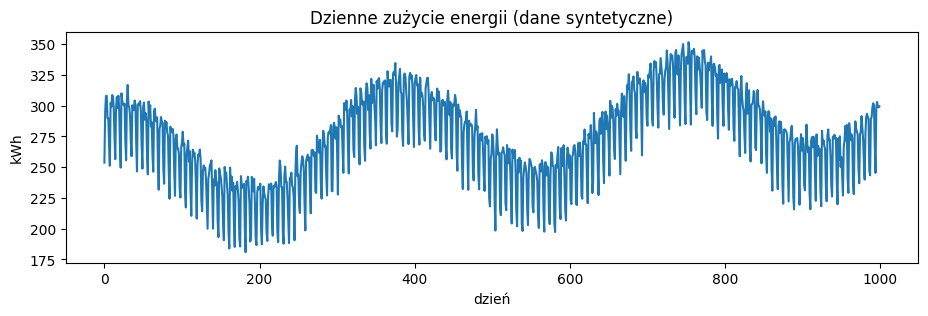

In [ ]:
import os, pandas as pd

SIGMA = 6.0

def sygnal_det(n=1000):
    daty = pd.date_range('2023-01-01', periods=n, freq='D')
    tyg = np.array([12, 14, 13, 12, 8, -22, -37], float); tyg -= tyg.mean()
    doy = daty.dayofyear.values
    return daty, 250 + 0.05*np.arange(n) + tyg[daty.dayofweek.values] + 40*np.cos(2*np.pi*(doy-15)/365.25)

PLIK_CSV = 'zuzycie_energii.csv'
if os.path.exists(PLIK_CSV):
    seria = pd.read_csv(PLIK_CSV)['zuzycie_kwh'].values.astype(np.float32)
    print('Wczytano', PLIK_CSV, '-', len(seria), 'dni')
else:
    daty, syg = sygnal_det(1000)
    y = np.round(syg + np.random.default_rng(42).normal(0, SIGMA, 1000), 2)
    pd.DataFrame({'data': daty.strftime('%Y-%m-%d'), 'zuzycie_kwh': y}).to_csv(PLIK_CSV, index=False)
    seria = y.astype(np.float32)
    print('Nie znaleziono pliku - wygenerowano i zapisano', PLIK_CSV)

plt.figure(figsize=(11,3)); plt.plot(seria)
plt.title('Dzienne zużycie energii (dane syntetyczne)'); plt.xlabel('dzień'); plt.ylabel('kWh'); plt.show()

## 3. Podział chronologiczny i standaryzacja (bez przecieku)

In [3]:
n=len(seria); i_tr=int(0.7*n); i_va=int(0.85*n)
mu, sd = seria[:i_tr].mean(), seria[:i_tr].std()
s = (seria - mu) / sd
print(f'Trening: 0..{i_tr}  Walidacja: {i_tr}..{i_va}  Test: {i_va}..{n}')

Trening: 0..700  Walidacja: 700..850  Test: 850..1000


## 4. Okna wejście–cel

Okno `OKNO` ostatnich dni jako wejście, następny dzień jako cel. Okno warto dobrać
tak, by objąć okres sezonowy (tu ≥ 7 dni).

In [4]:
OKNO = 28
def zrob_okna(s, okno, i_lo, i_hi):
    X, Y = [], []
    for i in range(max(okno, i_lo), i_hi):
        X.append(s[i-okno:i]); Y.append(s[i])
    return np.array(X,np.float32)[...,None], np.array(Y,np.float32)[:,None]

Xtr,Ytr = zrob_okna(s, OKNO, OKNO, i_tr)
Xva,Yva = zrob_okna(s, OKNO, i_tr, i_va)
Xte,Yte = zrob_okna(s, OKNO, i_va, n)
to_t = lambda a: torch.tensor(a).to(DEVICE)
Xtr,Ytr,Xva,Yva,Xte,Yte = map(to_t, [Xtr,Ytr,Xva,Yva,Xte,Yte])
print('kształty:', Xtr.shape, Xva.shape, Xte.shape)

kształty: torch.Size([672, 28, 1]) torch.Size([150, 28, 1]) torch.Size([150, 28, 1])


## 5. Model GRU i uczenie

Wybieramy model o najniższej stracie walidacyjnej (wczesne zatrzymanie w prostej formie).
Zmiana względem ćwiczenia: `trenuj` zapisuje także stratę treningową (liczoną po każdej epoce w trybie `eval`,
tą samą miarą co walidacyjna) oraz numer najlepszej epoki. Dodatkowe przejście po zbiorze treningowym nie zużywa
liczb losowych, więc przebieg uczenia jest taki sam jak w wersji oryginalnej. Argument `dane` pozwala w sekcji 10
trenować na innych oknach; domyślnie używane są zmienne globalne.

In [ ]:
class ModelGRU(nn.Module):
    def __init__(self, hidden=32):
        super().__init__()
        self.rnn = nn.GRU(1, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, 1)
    def forward(self, x):
        out, _ = self.rnn(x); return self.fc(out[:, -1, :])

def trenuj(model, epoki=40, lr=1e-2, batch=64, dane=None):
    Xtr_, Ytr_, Xva_, Yva_ = dane if dane is not None else (Xtr, Ytr, Xva, Yva)
    model = model.to(DEVICE); opt = torch.optim.Adam(model.parameters(), lr=lr); L = nn.MSELoss()
    best = 1e9; best_state = None; best_ep = None; hist = []; hist_tr = []
    for ep in range(epoki):
        model.train(); perm = torch.randperm(len(Xtr_))
        for i in range(0, len(Xtr_), batch):
            idx = perm[i:i+batch]; opt.zero_grad()
            L(model(Xtr_[idx]), Ytr_[idx]).backward(); opt.step()
        model.eval()
        with torch.no_grad():
            tr = L(model(Xtr_), Ytr_).item(); v = L(model(Xva_), Yva_).item()
        hist_tr.append(tr); hist.append(v)
        if v < best:
            best = v; best_ep = ep + 1
            best_state = {k: val.clone() for k, val in model.state_dict().items()}
    model.load_state_dict(best_state)
    return model, hist, hist_tr, best_ep

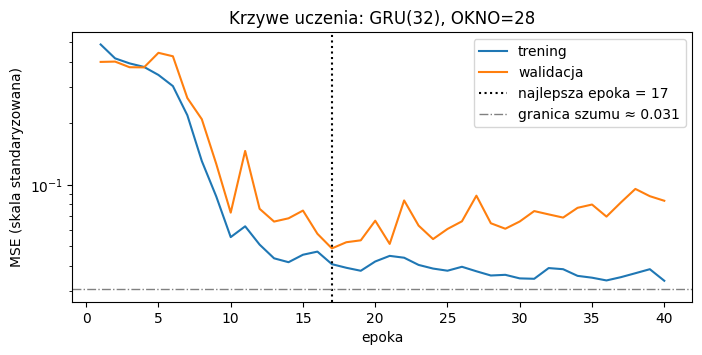

Najlepsza epoka (min straty walidacyjnej): 17 z 40
  epoka 17: trening 0.0408, walidacja 0.0487
  epoka 40: trening 0.0338, walidacja 0.0833
  najniższy trening 0.0338 (epoka 40)
  granica szumu (MSE std.): 0.0307


In [ ]:
model, hist, hist_tr, best_ep = trenuj(ModelGRU(32))

ep = np.arange(1, len(hist)+1)
gran_szumu_std = (SIGMA/sd)**2
plt.figure(figsize=(8,3.5))
plt.plot(ep, hist_tr, label='trening')
plt.plot(ep, hist, label='walidacja')
plt.axvline(best_ep, color='k', ls=':', label=f'najlepsza epoka = {best_ep}')
plt.axhline(gran_szumu_std, color='gray', ls='-.', lw=1, label=f'granica szumu ≈ {gran_szumu_std:.3f}')
plt.yscale('log'); plt.xlabel('epoka'); plt.ylabel('MSE (skala standaryzowana)')
plt.title('Krzywe uczenia: GRU(32), OKNO=28'); plt.legend(); plt.show()

print(f'Najlepsza epoka (min straty walidacyjnej): {best_ep} z {len(hist)}')
print(f'  epoka {best_ep}: trening {hist_tr[best_ep-1]:.4f}, walidacja {hist[best_ep-1]:.4f}')
print(f'  epoka {len(hist)}: trening {hist_tr[-1]:.4f}, walidacja {hist[-1]:.4f}')
print(f'  najniższy trening {min(hist_tr):.4f} (epoka {int(np.argmin(hist_tr))+1})')
print(f'  granica szumu (MSE std.): {gran_szumu_std:.4f}')

## 6. Predykcja na teście (w oryginalnej skali)

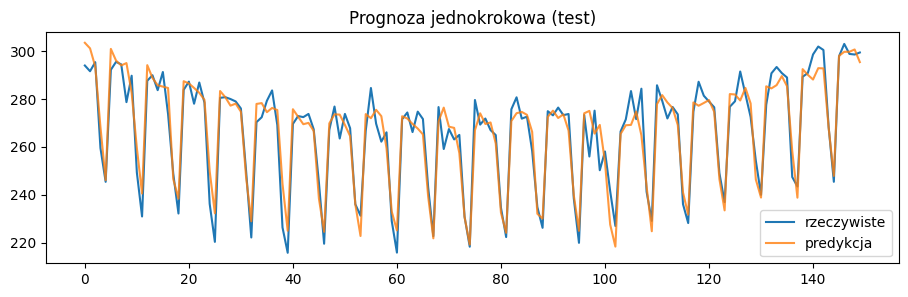

In [7]:
model.eval()
with torch.no_grad(): pred = model(Xte).cpu().numpy().ravel()
pred_raw = pred*sd + mu
true_raw = Yte.cpu().numpy().ravel()*sd + mu

plt.figure(figsize=(11,3))
plt.plot(true_raw, label='rzeczywiste')
plt.plot(pred_raw, label='predykcja', alpha=0.8)
plt.legend(); plt.title('Prognoza jednokrokowa (test)'); plt.show()

## 7. Porównanie z baseline'ami

Baseline liczymy na surowym szeregu, w oryginalnej skali.

In [8]:
def mae(a,b): return float(np.mean(np.abs(a-b)))
def rmse(a,b): return float(np.sqrt(np.mean((a-b)**2)))

tgt = np.arange(i_va, n)
naive    = seria[tgt-1]
seasonal = seria[tgt-7]
ma = np.array([seria[i-OKNO:i].mean() for i in tgt], np.float32)

print(f'{"metoda":16s}  MAE    RMSE')
print(f'{"RNN (GRU)":16s} {mae(true_raw,pred_raw):5.2f}  {rmse(true_raw,pred_raw):5.2f}')
print(f'{"naiwny (t-1)":16s} {mae(true_raw,naive):5.2f}  {rmse(true_raw,naive):5.2f}')
print(f'{"sezonowy (t-7)":16s} {mae(true_raw,seasonal):5.2f}  {rmse(true_raw,seasonal):5.2f}')
print(f'{"śr. ruchoma":16s} {mae(true_raw,ma):5.2f}  {rmse(true_raw,ma):5.2f}')

metoda            MAE    RMSE
RNN (GRU)         5.32   6.84
naiwny (t-1)     17.40  24.16
sezonowy (t-7)    7.17   9.14
śr. ruchoma      17.31  21.54


## 8. Prognoza wielokrokowa (rekurencyjna)

Prognozę na `H` dni budujemy rekurencyjnie: wyjście modelu wraca na wejście.

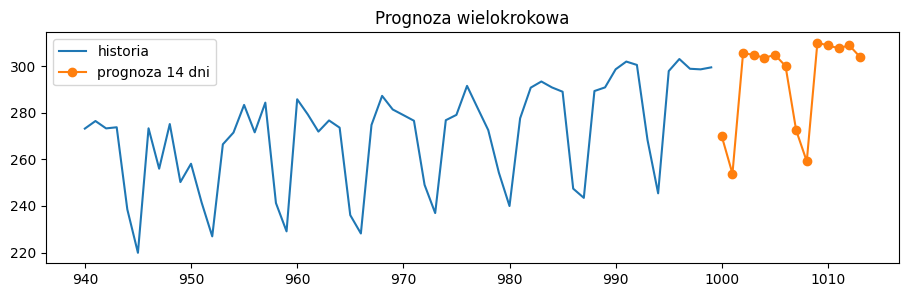

In [9]:
H = 14
okno = s[n-OKNO:].tolist()
preds = []
model.eval()
for _ in range(H):
    x = torch.tensor(np.array(okno[-OKNO:],np.float32).reshape(1,OKNO,1)).to(DEVICE)
    with torch.no_grad(): nx = model(x).item()
    preds.append(nx); okno.append(nx)
preds_raw = np.array(preds)*sd + mu

plt.figure(figsize=(11,3))
plt.plot(range(n-60, n), seria[n-60:], label='historia')
plt.plot(range(n, n+H), preds_raw, 'o-', label=f'prognoza {H} dni')
plt.legend(); plt.title('Prognoza wielokrokowa'); plt.show()

## 8b. Ocena wielokrokowa na zbiorze testowym (rolling origin)

Z każdego z punktów startowych `t0` (co `H = 14` dni, w zbiorze testowym) budujemy prognozę na dni `t0 … t0+H-1`
korzystając wyłącznie z danych znanych przed `t0`; porównujemy ją z prawdą. Dla `t0 = 850, 864, …, 976` daje to
10 okien po 14 dni = 140 dni testu (ostatnie 10 dni nie tworzą pełnego okna i nie są użyte).
Trzy metody oceniane są na tych samych dniach i tym samym horyzoncie:

* **GRU** — rekurencyjnie: każda prognoza wraca na wejście okna (błąd się kumuluje);
* **naiwny** — ostatnia znana wartość `y[t0-1]` powtórzona 14 dni;
* **sezonowy** — ostatni znany tydzień `y[t0-7 … t0-1]` powtórzony dwa razy.

In [ ]:
H = 14
starty = np.arange(i_va, n - H + 1, H)
print('punkty startowe:', starty.tolist(), '| liczba:', len(starty), '| dni testu użytych:', len(starty)*H)
Y_multi = np.stack([seria[t0:t0+H] for t0 in starty])

def prognoza_gru(m, okno, t0, H=H):
    m.eval()
    w = list(s[t0-okno:t0]); out = []
    for _ in range(H):
        x = torch.tensor(np.array(w[-okno:], np.float32).reshape(1, okno, 1)).to(DEVICE)
        with torch.no_grad(): nx = m(x).item()
        out.append(nx); w.append(nx)
    return np.array(out) * sd + mu

def prognoza_naiwna(t0, H=H):
    return np.full(H, seria[t0-1], dtype=np.float64)

def prognoza_sezonowa(t0, H=H):
    ost = seria[t0-7:t0]
    return np.array([ost[h % 7] for h in range(H)], dtype=np.float64)

P_gru = np.stack([prognoza_gru(model, OKNO, t0) for t0 in starty])
P_naw = np.stack([prognoza_naiwna(t0) for t0 in starty])
P_sez = np.stack([prognoza_sezonowa(t0) for t0 in starty])
assert P_gru.shape == P_naw.shape == P_sez.shape == Y_multi.shape
print('kształt prognoz:', P_gru.shape)

punkty startowe: [850, 864, 878, 892, 906, 920, 934, 948, 962, 976] | liczba: 10 | dni testu użytych: 140
kształt prognoz: (10, 14)


## 9. Tabela MAE / RMSE i wykres MAE w funkcji horyzontu

Jednokrokowo: wszystkie 150 dni testu (jak w sekcji 7). Wielokrokowo: 10 startów × 14 dni = 140 dni.
metoda             | 1-krok MAE  RMSE | 14-krok MAE  RMSE
GRU (OKNO=28)      |      5.32  6.84 |      7.87 10.14
naiwny (t-1)       |     17.40 24.16 |     19.70 26.88
sezonowy (t-7)     |      7.17  9.14 |      8.05 10.09
śr. ruchoma (28)   |     17.31 21.54 |         —     —

Kontrola — jednokrokowo na tych samych 140 dniach co wielokrokowo:
GRU (OKNO=28)      |      5.41  6.93
naiwny (t-1)       |     17.71 24.36
sezonowy (t-7)     |      7.14  9.09


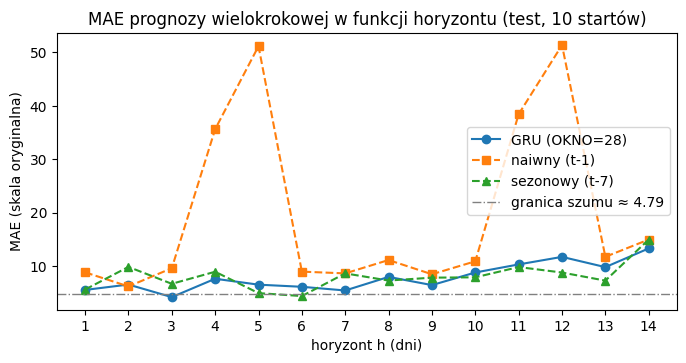

MAE(h), h=1..14:
  GRU (OKNO=28)     5.52  6.53  4.18  7.61  6.51  6.11  5.42  7.96  6.43  8.79 10.30 11.71  9.79 13.29
  naiwny (t-1)      8.82  6.18  9.59 35.60 51.14  8.95  8.62 11.12  8.45 10.88 38.41 51.33 11.72 14.95
  sezonowy (t-7)    5.59  9.83  6.67  8.93  4.93  4.38  8.62  7.28  7.82  7.89  9.80  8.78  7.26 14.95


In [ ]:
k = len(starty) * H
print('Jednokrokowo: wszystkie 150 dni testu (jak w sekcji 7). Wielokrokowo: 10 startów × 14 dni = 140 dni.')
print(f'{"metoda":18s} | 1-krok MAE  RMSE | {H}-krok MAE  RMSE')
wiersze = [('GRU (OKNO=%d)' % OKNO, pred_raw, P_gru), ('naiwny (t-1)', naive, P_naw), ('sezonowy (t-7)', seasonal, P_sez)]
for nm, p1, pm in wiersze:
    print(f'{nm:18s} | {mae(true_raw,p1):9.2f} {rmse(true_raw,p1):5.2f} | {mae(Y_multi,pm):9.2f} {rmse(Y_multi,pm):5.2f}')
print(f'{"śr. ruchoma (28)":18s} | {mae(true_raw,ma):9.2f} {rmse(true_raw,ma):5.2f} | {"—":>9s} {"—":>5s}')

print('\nKontrola — jednokrokowo na tych samych 140 dniach co wielokrokowo:')
for nm, p1, _ in wiersze:
    print(f'{nm:18s} | {mae(true_raw[:k],p1[:k]):9.2f} {rmse(true_raw[:k],p1[:k]):5.2f}')

GRANICA = SIGMA*np.sqrt(2/np.pi)
mae_h = {nm: np.abs(pm - Y_multi).mean(axis=0) for nm, _, pm in wiersze}
hh = np.arange(1, H+1)
plt.figure(figsize=(8,3.6))
for (nm, _, _), st in zip(wiersze, ['o-', 's--', '^--']):
    plt.plot(hh, mae_h[nm], st, label=nm)
plt.axhline(GRANICA, color='gray', ls='-.', lw=1, label=f'granica szumu ≈ {GRANICA:.2f}')
plt.xlabel('horyzont h (dni)'); plt.ylabel('MAE (skala oryginalna)'); plt.xticks(hh)
plt.title('MAE prognozy wielokrokowej w funkcji horyzontu (test, 10 startów)'); plt.legend(); plt.show()
print('MAE(h), h=1..14:')
for nm in mae_h: print(f'  {nm:16s}', ' '.join(f'{v:5.2f}' for v in mae_h[nm]))

## 10. Wpływ długości okna

`OKNO ∈ {3, 7, 28}`, każdy wariant na 2 ziarnach (`torch.manual_seed(0)` i `(1)`). Dni walidacyjne i testowe są
identyczne dla wszystkich okien (zmienia się tylko liczba dni wejściowych). Najlepsze okno wybieramy według
**średniej straty walidacyjnej** (MSE w skali standaryzowanej, minimum z epok) — nie według testu.

In [12]:
def przygotuj(okno):
    a = zrob_okna(s, okno, okno, i_tr); b = zrob_okna(s, okno, i_tr, i_va); c = zrob_okna(s, okno, i_va, n)
    return (to_t(a[0]), to_t(a[1]), to_t(b[0]), to_t(b[1])), to_t(c[0])

OKNA = (3, 7, 28); ZIARNA = (0, 1)
WYN = {}; MAEH = {}
for okno_ in OKNA:
    dane_, Xte_ = przygotuj(okno_)
    yv = dane_[3].cpu().numpy().ravel() * sd + mu
    for seed in ZIARNA:
        torch.manual_seed(seed)
        m, hv, ht, be = trenuj(ModelGRU(32), dane=dane_)
        m.eval()
        with torch.no_grad():
            pv = m(dane_[2]).cpu().numpy().ravel() * sd + mu
            pt = m(Xte_).cpu().numpy().ravel() * sd + mu
        P = np.stack([prognoza_gru(m, okno_, t0) for t0 in starty])
        WYN[(okno_, seed)] = dict(najl_ep=be, val_mse=min(hv), val_mae=mae(yv, pv),
                                  te1_mae=mae(true_raw, pt), te1_rmse=rmse(true_raw, pt),
                                  teH_mae=mae(Y_multi, P), teH_rmse=rmse(Y_multi, P))
        MAEH[(okno_, seed)] = np.abs(P - Y_multi).mean(axis=0)
        print(f'OKNO={okno_:2d} ziarno={seed}: najlepsza epoka {be:2d}, val MSE(std) {min(hv):.4f}')

OKNO= 3 ziarno=0: najlepsza epoka 15, val MSE(std) 0.1930
OKNO= 3 ziarno=1: najlepsza epoka 34, val MSE(std) 0.2232
OKNO= 7 ziarno=0: najlepsza epoka 34, val MSE(std) 0.0745
OKNO= 7 ziarno=1: najlepsza epoka 37, val MSE(std) 0.0562
OKNO=28 ziarno=0: najlepsza epoka 17, val MSE(std) 0.0487
OKNO=28 ziarno=1: najlepsza epoka 38, val MSE(std) 0.0623


val MSE = strata walidacyjna w skali standaryzowanej; pozostałe metryki w skali oryginalnej.
  OKNO ziarno | ep.  val MSE  val MAE | MAE 1-krok RMSE 1-krok |  MAE 14d  RMSE 14d
     3      0 |  15   0.1930    12.31 |      12.03       15.58 |    38.91     46.40
     3      1 |  34   0.2232    13.24 |      11.79       15.63 |    41.88     50.14
     3    śr. |  24   0.2081    12.77 |      11.91       15.61 |    40.39     48.27
     7      0 |  34   0.0745     7.57 |       6.02        7.82 |     7.15      9.35
     7      1 |  37   0.0562     6.62 |       5.91        7.76 |     7.13      9.16
     7    śr. |  36   0.0654     7.09 |       5.96        7.79 |     7.14      9.26
    28      0 |  17   0.0487     5.95 |       5.32        6.84 |     7.87     10.14
    28      1 |  38   0.0623     6.92 |       5.54        7.21 |    12.41     15.06
    28    śr. |  28   0.0555     6.43 |       5.43        7.02 |    10.14     12.60
naiwny        |                       |      17.40       24.16 |   

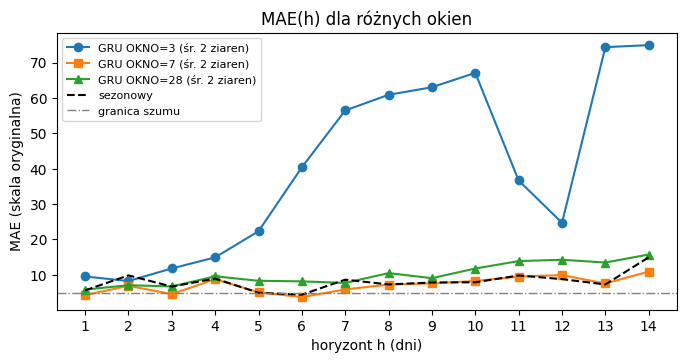

Kontrola: OKNO=28, ziarno 0 → val MSE 0.0487, najlepsza epoka 17 (sekcja 5: 0.0487, epoka 17); wartości powinny się zgadzać.


In [13]:
kol = ['najl_ep', 'val_mse', 'val_mae', 'te1_mae', 'te1_rmse', 'teH_mae', 'teH_rmse']
print('val MSE = strata walidacyjna w skali standaryzowanej; pozostałe metryki w skali oryginalnej.')
print(f'{"OKNO":>6s} {"ziarno":>6s} | {"ep.":>3s} {"val MSE":>8s} {"val MAE":>8s} | {"MAE 1-krok":>10s} {"RMSE 1-krok":>11s} | {"MAE 14d":>8s} {"RMSE 14d":>9s}')
for okno_ in OKNA:
    for seed in ZIARNA:
        r = WYN[(okno_, seed)]
        print(f'{okno_:6d} {seed:6d} | {r["najl_ep"]:3d} {r["val_mse"]:8.4f} {r["val_mae"]:8.2f} | {r["te1_mae"]:10.2f} {r["te1_rmse"]:11.2f} | {r["teH_mae"]:8.2f} {r["teH_rmse"]:9.2f}')
    sr = {kk: np.mean([WYN[(okno_, sd_)][kk] for sd_ in ZIARNA]) for kk in kol}
    print(f'{okno_:6d} {"śr.":>6s} | {sr["najl_ep"]:3.0f} {sr["val_mse"]:8.4f} {sr["val_mae"]:8.2f} | {sr["te1_mae"]:10.2f} {sr["te1_rmse"]:11.2f} | {sr["teH_mae"]:8.2f} {sr["teH_rmse"]:9.2f}')
print(f'{"naiwny":>6s} {"":>6s} | {"":>3s} {"":>8s} {"":>8s} | {mae(true_raw,naive):10.2f} {rmse(true_raw,naive):11.2f} | {mae(Y_multi,P_naw):8.2f} {rmse(Y_multi,P_naw):9.2f}')
print(f'{"sezon.":>6s} {"":>6s} | {"":>3s} {"":>8s} {"":>8s} | {mae(true_raw,seasonal):10.2f} {rmse(true_raw,seasonal):11.2f} | {mae(Y_multi,P_sez):8.2f} {rmse(Y_multi,P_sez):9.2f}')

srednia_val = {o: np.mean([WYN[(o, z)]['val_mse'] for z in ZIARNA]) for o in OKNA}
najlepsze_okno = min(srednia_val, key=srednia_val.get)
print('\nŚrednia strata walidacyjna (MSE std.):', {o: round(float(v), 4) for o, v in srednia_val.items()})
print(f'>>> Najlepsze okno wybrane według walidacji: OKNO = {najlepsze_okno}')
print('    (test MAE 1-krok / 14d dla tego okna: '
      f'{np.mean([WYN[(najlepsze_okno, z)]["te1_mae"] for z in ZIARNA]):.2f} / {np.mean([WYN[(najlepsze_okno, z)]["teH_mae"] for z in ZIARNA]):.2f}, tylko informacyjnie)')

print('\nRóżnice między oknami vs rozrzut między ziarnami (|ziarno0 - ziarno1|):')
for kk in ['val_mse', 'te1_mae', 'teH_mae']:
    sr_ok = [np.mean([WYN[(o, z)][kk] for z in ZIARNA]) for o in OKNA]
    miedzy = max(sr_ok) - min(sr_ok)
    ziarna = max(abs(WYN[(o, 0)][kk] - WYN[(o, 1)][kk]) for o in OKNA)
    print(f'  {kk:8s}: rozstęp średnich między oknami = {miedzy:.4f}, największy rozrzut ziaren = {ziarna:.4f}, stosunek = {miedzy/max(ziarna,1e-12):.1f}')

plt.figure(figsize=(8,3.6))
for okno_, st in zip(OKNA, ['o-', 's-', '^-']):
    plt.plot(hh, np.mean([MAEH[(okno_, z)] for z in ZIARNA], axis=0), st, label=f'GRU OKNO={okno_} (śr. 2 ziaren)')
plt.plot(hh, mae_h['sezonowy (t-7)'], 'k--', label='sezonowy'); plt.axhline(GRANICA, color='gray', ls='-.', lw=1, label='granica szumu')
plt.xlabel('horyzont h (dni)'); plt.ylabel('MAE (skala oryginalna)'); plt.xticks(hh); plt.legend(fontsize=8)
plt.title('MAE(h) dla różnych okien'); plt.show()

if (28, 0) in WYN:
    print(f'Kontrola: OKNO=28, ziarno 0 → val MSE {WYN[(28,0)]["val_mse"]:.4f}, najlepsza epoka {WYN[(28,0)]["najl_ep"]} (sekcja 5: {min(hist):.4f}, epoka {best_ep}); '
          'wartości powinny się zgadzać.')

## 11. Dane do interpretacji

In [ ]:
sygnal = sygnal_det(n)[1]
mae_idealny = mae(seria[i_va:], sygnal[i_va:])
g1 = mae(true_raw, pred_raw)
print(f'Granica szumu (MAE idealnego predyktora, sigma={SIGMA:g}): {GRANICA:.3f}; empirycznie na teście: {mae_idealny:.3f}')
print(f'GRU jednokrokowo: MAE {g1:.2f} → {g1-GRANICA:+.2f} względem granicy teoretycznej ({(g1/GRANICA-1):+.0%})')
print(f'GRU jednokrokowo vs naiwny: {g1:.2f} vs {mae(true_raw,naive):.2f}; vs sezonowy: {mae(true_raw,seasonal):.2f}')
gH = mae(Y_multi, P_gru)
print(f'GRU {H}-krok: MAE {gH:.2f}; naiwny {mae(Y_multi,P_naw):.2f}; sezonowy {mae(Y_multi,P_sez):.2f}')
print(f'MAE GRU h=1: {mae_h[wiersze[0][0]][0]:.2f}, h={H}: {mae_h[wiersze[0][0]][-1]:.2f} (narastanie błędu w prognozie rekurencyjnej)')

Granica szumu (MAE idealnego predyktora, sigma=6): 4.787; empirycznie na teście: 4.473
GRU jednokrokowo: MAE 5.32 → +0.53 względem granicy teoretycznej (+11%)
GRU jednokrokowo vs naiwny: 5.32 vs 17.40; vs sezonowy: 7.17
GRU 14-krok: MAE 7.87; naiwny 19.70; sezonowy 8.05
MAE GRU h=1: 5.52, h=14: 13.29 (narastanie błędu w prognozie rekurencyjnej)
